# Virtual testing: pursuit tracking

Test the tracking logic from `flight.py` without hardware. Run the cells in order.

The runner follows a set path, and a simulated pursuer follows the position commands at a fixed height of 0.2 m. This tests tracking and data-loss handling, not flight dynamics, takeoff, or landing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 11})

## 1. Settings

These settings match `flight.py`. The target sits 0.3 m behind the runner’s travel direction. When it stops, we keep its last direction. Before any motion, we use the direction from pursuer to runner.

`response_time` controls the simulated drone's lag. Larger values mean a slower response; this value has not been measured on our drone.

In [2]:
follow_distance = 0.3  # Meters behind the runner.
tracking_height = 0.2
tracking_duration = 30.0
box_min = np.array([-1.0, -1.0, 0.15])
box_max = np.array([1.0, 1.0, 1.0])
max_step = 0.05
min_separation = 0.1
pursuer_max_age = 0.3
runner_max_age = 0.2  # Default used by get_latest(runner).
period = 0.1
response_time = 0.5


## 2. Tracking logic

Both this notebook and `flight.py` use `tracking_step()` from `tracking.py`.

1. Place the target 0.3 m behind the runner and clip the target to the box.
2. Move the command toward the target by at most `max_step`.
3. Stop pursuit if either checked path passes too close to the runner.

This limits command changes, not physical speed. It checks the runner's current position without predicting its motion.

In [3]:
from tracking import tracking_step, travel_direction, trailing_point


## 3. Simulate the drone

Each step, the pursuer moves partway toward the command. This adds lag but does not model inertia or overshoot.

We advance simulated time instead of waiting. For data-loss tests, we stop refreshing a measurement and exit when it becomes too old. The simulation ends there; descent is not modeled.

In [4]:
def simulate(runner_path, initial_position, duration=tracking_duration,
             dropout_body=None, dropout_at=None):
    p_pursuer = np.array(initial_position, dtype=float)
    command = np.array([*p_pursuer, tracking_height])
    previous_command = command[:2].copy()
    measured_pursuer = p_pursuer.copy()
    measured_runner = np.array(runner_path(0.0), dtype=float)
    runner_velocity = None
    runner_direction = measured_runner - p_pursuer
    runner_direction /= np.linalg.norm(runner_direction)
    last_update = {"pursuer": 0.0, "runner": 0.0}
    response_fraction = 1.0 - np.exp(-period / response_time)
    records = []
    reason = "Completed"
    stop_time = duration

    for t in np.arange(0.0, duration, period):
        p_runner = np.array(runner_path(t), dtype=float)
        for body in ("pursuer", "runner"):
            missing = (body == dropout_body and dropout_at is not None
                       and t >= dropout_at)
            if not missing:
                previous_update = last_update[body]
                last_update[body] = t
                if body == "pursuer":
                    measured_pursuer = p_pursuer.copy()
                else:
                    dt = t - previous_update
                    if dt > 0:
                        velocity = (p_runner - measured_runner) / dt
                        runner_velocity = velocity if runner_velocity is None else (
                            0.3 * velocity + 0.7 * runner_velocity)
                    measured_runner = p_runner.copy()

        if (t - last_update["pursuer"] > pursuer_max_age
                or t - last_update["runner"] > runner_max_age):
            reason, stop_time = "Stale motion capture", t
            break

        runner_direction = travel_direction(runner_velocity, runner_direction)
        follow_point = trailing_point(measured_runner, runner_direction, follow_distance)
        p_next, target, too_close = tracking_step(
            command, measured_pursuer, measured_runner, runner_direction, follow_distance,
            box_min, box_max, max_step, min_separation)
        if too_close:
            reason, stop_time = "Minimum separation", t
            break

        command[:2] = p_next
        records.append({
            "time": t,
            "runner": p_runner.copy(),
            "pursuer": p_pursuer.copy(),
            "command": command[:2].copy(),
            "target": target.copy(),
            "follow_point": follow_point.copy(),
            "direction": runner_direction.copy(),
            "step": np.linalg.norm(command[:2] - previous_command),
            "separation": np.linalg.norm(p_runner - p_pursuer),
            "error": np.linalg.norm(target - p_pursuer),
        })
        previous_command = command[:2].copy()
        p_pursuer += response_fraction * (command[:2] - p_pursuer)

    result = {key: np.array([row[key] for row in records])
              for key in ("time", "runner", "pursuer", "command", "target",
                          "step", "separation", "error", "follow_point", "direction")}
    result.update(reason=reason, stop_time=stop_time)
    return result


## 4. Run the tests

Try a stationary runner, a straight line, a circle, a square, an out-of-bounds target, and a close approach.

The two data-loss tests stop updating measurements at 2 seconds. Tracking should exit after the relevant timeout.

Every pursuer starts at `[-0.8, 0.8]`. From here, the original close-approach path stays clear; we check the separation guard separately.

In [5]:
def square_path(t):
    corners = np.array([[-0.3, -0.3], [0.3, -0.3],
                        [0.3, 0.3], [-0.3, 0.3]])
    progress = (t / 3) % 4
    side = int(progress)
    fraction = progress - side
    return corners[side] + fraction * (corners[(side + 1) % 4] - corners[side])


scenarios = {
    "Square": dict(runner_path=square_path, initial_position=[-0.8, 0.8]),
    "Stationary runner": dict(
        runner_path=lambda t: [0.5, 0.0], initial_position=[-0.8, 0.8]),
    "Straight line": dict(
        runner_path=lambda t: [0.1 + 0.015*t, 0.1], initial_position=[-0.8, 0.8]),
    "Circle": dict(
        runner_path=lambda t: [0.4*np.cos(0.4*t), 0.4*np.sin(0.4*t)],
        initial_position=[-0.8, 0.8]),
    "Runner outside box": dict(
        runner_path=lambda t: [1.5, 0.4], initial_position=[-0.8, 0.8]),
    "Close approach": dict(
        runner_path=lambda t: [0.15 - 0.1*t, 0.0], initial_position=[-0.8, 0.8]),
    "Lost runner data": dict(
        runner_path=lambda t: [0.5, 0.0], initial_position=[-0.8, 0.8],
        dropout_body="runner", dropout_at=2.0),
    "Lost pursuer data": dict(
        runner_path=lambda t: [0.5, 0.0], initial_position=[-0.8, 0.8],
        dropout_body="pursuer", dropout_at=2.0),
}
results = {name: simulate(**settings) for name, settings in scenarios.items()}

rows = ["| Scenario | Outcome | End time (s) | Last target error (m) |",
        "|---|---|---:|---:|"]
for name, result in results.items():
    error = f"{result['error'][-1]:.3f}" if len(result['time']) else "—"
    rows.append(f"| {name} | {result['reason']} | {result['stop_time']:.1f} | {error} |")
display(Markdown("\n".join(rows)))

| Scenario | Outcome | End time (s) | Last target error (m) |
|---|---|---:|---:|
| Square | Completed | 30.0 | 0.108 |
| Stationary runner | Completed | 30.0 | 0.000 |
| Straight line | Completed | 30.0 | 0.008 |
| Circle | Completed | 30.0 | 0.102 |
| Runner outside box | Completed | 30.0 | 0.000 |
| Close approach | Completed | 30.0 | 0.000 |
| Lost runner data | Stale motion capture | 2.2 | 0.399 |
| Lost pursuer data | Stale motion capture | 2.2 | 0.399 |

## 5. Plot a test

Change `selected` to choose a test. The left plot shows the paths; the right shows target error and runner separation before each response step. Crosses mark the last recorded positions.

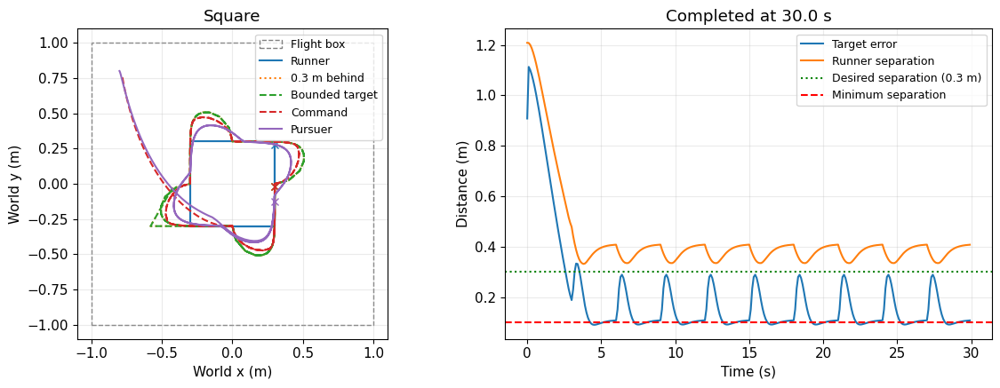

In [23]:
selected = "Square"
result = results[selected]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.add_patch(Rectangle(box_min[:2], *(box_max[:2] - box_min[:2]),
                       fill=False, linestyle="--", color="gray", label="Flight box"))
for key, label, style in [("runner", "Runner", "-"),
                          ("follow_point", "0.3 m behind", ":"),
                          ("target", "Bounded target", "--"),
                          ("command", "Command", "--"),
                          ("pursuer", "Pursuer", "-")]:
    path = result[key]
    if len(path):
        line, = ax.plot(path[:, 0], path[:, 1], style, label=label)
        ax.plot(*path[-1], "x", color=line.get_color())
ax.set(xlabel="World x (m)", ylabel="World y (m)", title=selected)
ax.set_aspect("equal", adjustable="box")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
axes[1].plot(result["time"], result["error"], label="Target error")
axes[1].plot(result["time"], result["separation"], label="Runner separation")
axes[1].axhline(follow_distance, color="green", linestyle=":",
                label="Desired separation (0.3 m)")
axes[1].axhline(min_separation, color="red", linestyle="--", label="Minimum separation")
axes[1].set(xlabel="Time (s)", ylabel="Distance (m)",
            title=f"{result['reason']} at {result['stop_time']:.1f} s")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Check the results

Check command limits, stationary tracking, box bounds, and expected exits. Passing these tests does not guarantee safe separation in every situation.

In [24]:
for name, result in results.items():
    assert len(result["time"]) > 0, f"{name}: no commands recorded"
    assert np.all(np.isfinite(result["command"])), name
    assert np.all(result["step"] <= max_step + 1e-10), name
    assert np.all(result["command"] >= box_min[:2] - 1e-10), name
    assert np.all(result["command"] <= box_max[:2] + 1e-10), name

for name in ("Stationary runner", "Straight line", "Circle", "Square", "Runner outside box"):
    assert results[name]["reason"] == "Completed", name
assert results["Stationary runner"]["error"][-1] < 0.01
boundary = results["Runner outside box"]
assert np.allclose(boundary["target"][-1],
                   np.clip(boundary["follow_point"][-1], box_min[:2], box_max[:2]))
assert np.isclose(boundary["target"][-1, 0], box_max[0])
# This runner path stays clear of the new starting position.
assert results["Close approach"]["reason"] == "Completed"
_, _, too_close = tracking_step(
    np.array([0.0, 0.0, tracking_height]), np.array([0.0, 0.0]),
    np.array([0.05, 0.0]), np.array([1.0, 0.0]), follow_distance,
    box_min, box_max, max_step, min_separation)
assert too_close
for name, age_limit in (("Lost runner data", runner_max_age),
                        ("Lost pursuer data", pursuer_max_age)):
    assert results[name]["reason"] == "Stale motion capture", name
    assert 2.0 <= results[name]["stop_time"] <= 2.0 + age_limit + period + 1e-9
print("Passed: command limits, stationary convergence, bounds, separation exit, and both data-loss exits.")
for result in results.values():
    delta = result["runner"] - result["follow_point"]
    # Fresh-data runs use the current runner position.
    if result["reason"] != "Stale motion capture":
        assert np.allclose(np.linalg.norm(delta, axis=1), follow_distance)
        assert np.allclose(delta, follow_distance * result["direction"])
assert np.allclose(travel_direction([0, 0], [0, 1]), [0, 1])
assert np.allclose(trailing_point([1, 1], np.array([0, 1]), 0.3), [1, 0.7])
print("Passed: trailing distance, direction, and stationary heading.")


Passed: command limits, stationary convergence, bounds, separation exit, and both data-loss exits.
Passed: trailing distance, direction, and stationary heading.


## Watch the tracking

Run this after choosing a test above. Press play to watch the recorded simulation. This is playback, not a live drone connection.

The purple star is the trailing point. The blue line shows forward travel direction. The green cross is the limited command toward the bounded target. At box edges, the command target is clipped, so it may differ from the star.

In [25]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

result = results[selected]
fig, ax = plt.subplots(figsize=(5, 5))
ax.add_patch(Rectangle(box_min[:2], *(box_max[:2] - box_min[:2]),
                       fill=False, linestyle="--", color="gray"))
paths = np.vstack([result["runner"], result["pursuer"],
                   box_min[None, :2], box_max[None, :2]])
ax.set_xlim(paths[:, 0].min() - 0.15, paths[:, 0].max() + 0.15)
ax.set_ylim(paths[:, 1].min() - 0.15, paths[:, 1].max() + 0.15)
ax.set_aspect("equal")
ax.set(xlabel="World x (m)", ylabel="World y (m)", title=selected)
ax.grid(alpha=0.2)
runner_dot, = ax.plot([], [], "o", color="tab:blue", label="Runner")
pursuer_dot, = ax.plot([], [], "o", color="tab:red", label="Pursuer")
follow_dot, = ax.plot([], [], "*", color="purple", markersize=12, label="0.3 m behind")
heading_line, = ax.plot([], [], color="tab:blue", linewidth=2, label="Travel direction")
follow_link, = ax.plot([], [], ":", color="purple", alpha=0.6)
command_dot, = ax.plot([], [], "x", color="tab:green", label="Command")
runner_trail, = ax.plot([], [], color="tab:blue", alpha=0.35)
pursuer_trail, = ax.plot([], [], color="tab:red", alpha=0.35)
clock = ax.text(0.03, 0.97, "", transform=ax.transAxes, va="top")
ax.legend(loc="lower right", fontsize=9)


def update(frame):
    for dot, key in ((runner_dot, "runner"), (pursuer_dot, "pursuer"),
                     (command_dot, "command"), (follow_dot, "follow_point")):
        x, y = result[key][frame]
        dot.set_data([x], [y])
    for trail, key in ((runner_trail, "runner"), (pursuer_trail, "pursuer")):
        trail.set_data(result[key][:frame + 1, 0], result[key][:frame + 1, 1])
    runner = result["runner"][frame]
    forward = runner + 0.15 * result["direction"][frame]
    heading_line.set_data([runner[0], forward[0]], [runner[1], forward[1]])
    point = result["follow_point"][frame]
    follow_link.set_data([runner[0], point[0]], [runner[1], point[1]])
    clock.set_text(f"Time: {result['time'][frame]:.1f} s")
    return runner_dot, pursuer_dot, command_dot, follow_dot, heading_line, follow_link, runner_trail, pursuer_trail, clock


animation = FuncAnimation(fig, update, frames=len(result["time"]),
                          interval=period * 1000, blit=False, repeat=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))
